Setup básico: importação das bibliotecas e leitura do arquivo de dados.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

arquivo = "dados.xlsx"
df = pd.read_excel(arquivo)
df.head()


,ID_Ensaio,Data_Hora,Tipo_Motor,Estrategia_Controle,Inversor,Nivel_Carga,Ganho_Kp,Ganho_Ki,Setpoint_Rotacao_rpm,Rotacao_Medida_rpm,Erro_Rotacao_rpm,Tensao_Linha_V,Corrente_A,Potencia_Ativa_kW,Fator_Potencia,THD_Corrente_Perc,Temperatura_Enrolamento_C,Vibracao_mm_s,Tempo_Resposta_ms,Status_Alarme
0,EN-00001,2025-05-22 06:19:00,Síncrono PM,Controle vetorial,Inversor B,Leve,1.371,0.542,1800,1771.4,-28.6,389.5,7.20,4.17,0.858,7.20,59.5,2.07,87.1,Normal
1,EN-00002,2025-07-23 16:21:00,Relutância síncrona,Controle vetorial,Inversor B,Pesada,1.775,0.610,2400,2385.1,-14.9,382.7,19.30,12.24,0.957,5.42,83.4,2.15,119.4,Normal
2,EN-00003,2025-03-15 13:20:00,Indução trifásico,Controle vetorial,Inversor B,Pesada,1.406,0.587,900,884.2,-15.8,364.6,11.14,6.32,0.899,5.39,84.9,3.03,106.4,Normal
3,EN-00004,2025-09-29 15:55:00,Síncrono PM,DTC,Inversor A,Sobrecarga,2.036,0.586,1500,1492.5,-7.5,397.1,17.65,12.02,0.990,5.86,93.3,2.29,59.7,Alerta
4,EN-00005,2025-12-31 19:12:00,Indução trifásico,Controle vetorial,Inversor B,Média,1.530,0.604,1800,1789.8,-10.2,368.6,12.91,6.87,0.834,7.32,66.8,2.37,134.4,Normal


Calcula a frequência absoluta e a frequência percentual de cada nível de carga e reúne as duas em uma única tabela.


In [ ]:
freq_abs = df['Nivel_Carga'].value_counts()
freq_percentual = (freq_abs / len(df)) * 100

tabela_freq = pd.DataFrame({
    'Frequência Absoluta': freq_abs,
    'Frequência Percentual (%)': freq_percentual.round(2)
}).sort_values('Frequência Absoluta', ascending=False)

tabela_freq


,Frequência Absoluta,Frequência Percentual (%)
Nivel_Carga,,
Média,412,39.24
Pesada,340,32.38
Leve,168,16.00
Sobrecarga,130,12.38


Gráfico de barras com a frequência absoluta e com a frequência percentual de cada nível de carga.


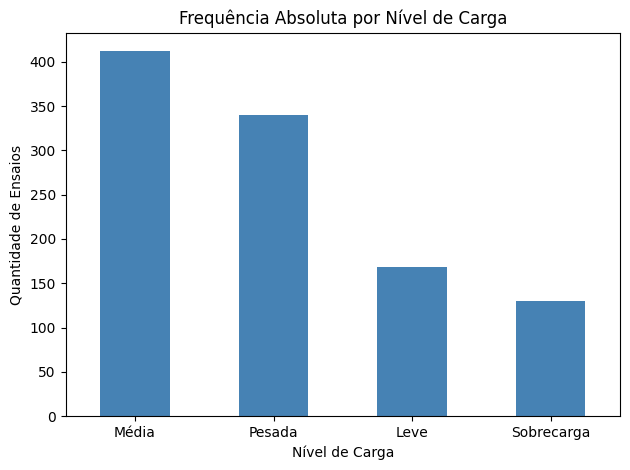

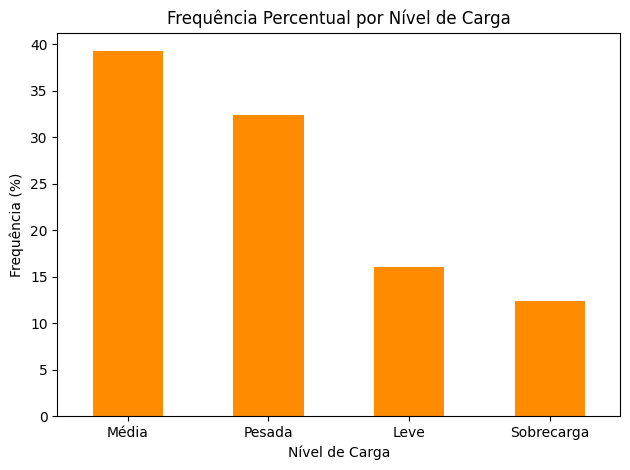

In [ ]:
tabela_freq['Frequência Absoluta'].plot(kind='bar', color='steelblue')
plt.title('Frequência Absoluta por Nível de Carga')
plt.xlabel('Nível de Carga')
plt.ylabel('Quantidade de Ensaios')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

tabela_freq['Frequência Percentual (%)'].plot(kind='bar', color='darkorange')
plt.title('Frequência Percentual por Nível de Carga')
plt.xlabel('Nível de Carga')
plt.ylabel('Frequência (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Medida resumo: moda
Como o Nível de Carga é uma variável qualitativa, a única medida de tendência central que faz sentido calcular é a moda.


In [ ]:
moda = df['Nivel_Carga'].mode()
print(f"Moda: {moda}")


Moda: 0    Média
Name: Nivel_Carga, dtype: object


**Interpretação:** a moda da variável Nível de Carga é `Média`, com 412 ocorrências. Isso indica que, na maior parte dos testes de acionamento, os motores foram avaliados operando em carga média. Em seguida aparecem os níveis `Pesada` (32,38%), `Leve` (16,00%) e `Sobrecarga` (12,38%), sendo este último o cenário menos frequente — o que é esperado, já que ensaios em sobrecarga costumam ser pontuais, feitos para testar limites do sistema, e não a condição normal de operação.
